### Requirements:

    sampling frequency = 200 Hz
    passband = 45-55 Hz
    maximum passband error = 15%
    lower stopband = 0-10 Hz
    upper stopband = 90-100 Hz
    maximum stopband attenuation = 20 dB

rho = 0.6
Passband error = % 5.18577107242092
Lower stopband (dB) = 16.447528650387245
Upper stopband (dB) = 16.44752865038724
-----------
rho = 0.7
Passband error = % 9.18178996263177
Lower stopband (dB) = 19.16607605452117
Upper stopband (dB) = 19.166076054521167
-----------
rho = 0.75
Passband error = % 12.876439866357236
Lower stopband (dB) = 20.893150242118313
Upper stopband (dB) = 20.893150242118313
-----------
rho = 0.8
Passband error = % 18.795154100488553
Lower stopband (dB) = 22.9934904329936
Upper stopband (dB) = 22.993490432993596
-----------
rho = 0.85
Passband error = % 28.550904419679025
Lower stopband (dB) = 25.67051930298436
Upper stopband (dB) = 25.67051930298436
-----------
rho = 0.9
Passband error = % 44.6023303134248
Lower stopband (dB) = 29.3843164317399
Upper stopband (dB) = 29.384316431739897
-----------


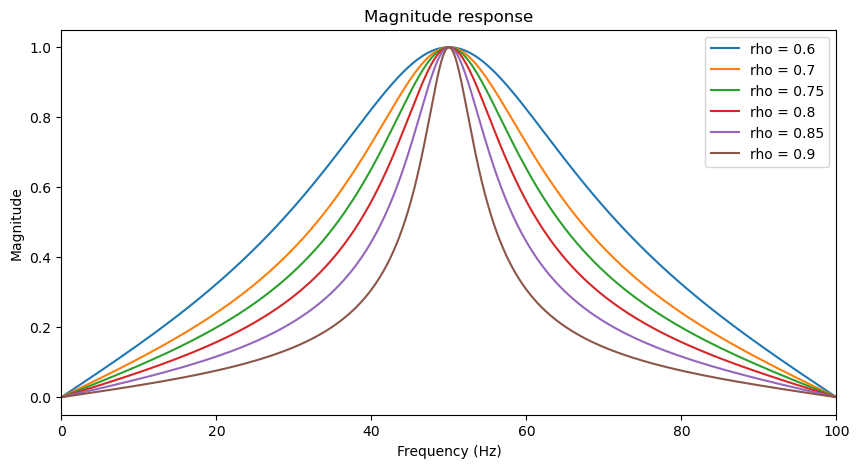

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

fs = 200
#zeros at 0 and 100 Hz
b = np.convolve([1, -1], [1, 1])

#Poles at 50 Hz
f0 = 50
theta0 = 2 * np.pi * f0 / fs
rhos = [0.6, 0.7, 0.75, 0.8, 0.85, 0.9]
plt.figure(figsize=(10, 5))
for rho in rhos:
    a = np.array([1, -2 * np.cos(theta0) * rho, rho ** 2])

    #normalizing coeeficients (gain50 Hz = 1)
    _, H50 = freqz(b, a, worN=[50], fs=fs)
    magnitude50 = np.abs(H50[0])
    b = b / magnitude50

    #frequency response
    f, H = freqz(b, a, worN=2048, fs=fs)
    magnitude = np.abs(H)
    plt.plot(f, magnitude, label = f"rho = {rho}")
    #passband error
    passband = (f >= 45) & (f <= 55)
    passband_error = np.max(np.abs(magnitude[passband] - 1)) * 100

    #stopbands attenuation
    lower_stopband = f <= 10
    upper_stopband = f >= 90
    lower_att_dB = -20 * np.log10(np.max(magnitude[lower_stopband]))
    upper_att_dB = -20 * np.log10(np.max(magnitude[upper_stopband]))
    print("rho =", rho)
    print("Passband error = %", passband_error)
    print("Lower stopband (dB) =", lower_att_dB)
    print("Upper stopband (dB) =", upper_att_dB)
    print("-----------")

plt.legend()
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Magnitude response")
plt.show()


rho = 0.75 satisfies both requirements

#### Conclusion:

As pole radius increases:

    Filter becomes more selective around 50 Hz

    Stopband attenuation improves

    Attenuation near 45 and 55 Hz becomes greater



### Applying IIR filter

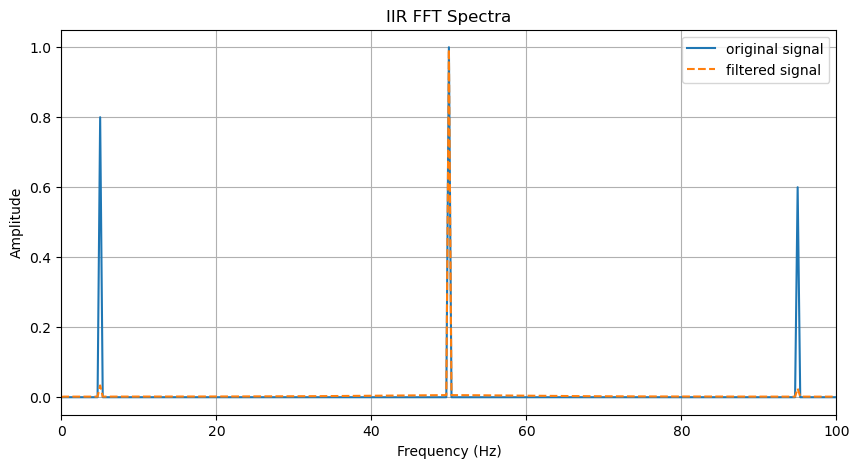

In [24]:
#Using the same signal from FIR band-pass design practice
fs, duration = 200, 3
N = fs * duration
t = np.arange(N) / fs
useful = np.sin(2 * np.pi * 50 * t)
low_noise = 0.8 * np.sin(2 * np.pi * 5 * t)
high_noise = 0.6 * np.sin(2 * np.pi * 95 * t)
x = useful + low_noise + high_noise

rho = 0.75
a = np.array([1, -2 * np.cos(theta0) * rho, rho ** 2])
_, H50 = freqz(b, a, worN=[50], fs=fs)
magnitude50 = np.abs(H50[0])
b = b / magnitude50
iir_out = lfilter(b, a, x)
freq_fft = np.fft.rfftfreq(N, d=1/fs)
amplitude_iir = np.abs(np.fft.rfft(iir_out)) / N
amplitude_iir[1:-1] *= 2
amplitude_fft = np.abs(np.fft.rfft(x)) / N
amplitude_fft[1:-1] *= 2
plt.figure(figsize=(10, 5))
plt.plot(freq_fft, amplitude_fft, label = "original signal")
plt.plot(freq_fft, amplitude_iir, label = "filtered signal", linestyle = "--")
plt.xlim(0, 100)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude")
plt.title("IIR FFT Spectra")
plt.grid(True)
plt.legend()
plt.show()

In [25]:
#calculating gains at specific frequencies
test_freqs = [5, 10, 45, 50, 55, 90, 95]
_, H_iir = freqz(b, a, worN=test_freqs, fs=fs)
gain_iir = np.abs(H_iir)
for freq, gain in zip(test_freqs, gain_iir):
    print(f"frequency (Hz) = {freq}\tIIR gain = {gain:.3f}")

frequency (Hz) = 5	IIR gain = 0.044
frequency (Hz) = 10	IIR gain = 0.091
frequency (Hz) = 45	IIR gain = 0.870
frequency (Hz) = 50	IIR gain = 1.000
frequency (Hz) = 55	IIR gain = 0.870
frequency (Hz) = 90	IIR gain = 0.091
frequency (Hz) = 95	IIR gain = 0.044


#### Comparing this filter with FIR filter:

The FIR filter performs better at 45 Hz and 55 Hz.

Both preserve 50 Hz with a gain of 1.

The FIR filter suppresses the actual interference at 5 Hz and 95 Hz more strongly.

However, the IIR filter performs slightly better at the stopband boundaries (10 Hz and 90 Hz).

The FIR is fourth-order, whereas the IIR is second-order. The IIR uses feedback and fewer coefficients, while the FIR has linear phase and constant group delay within its passband.

### Conclusion:

For this specific signal, I would choose the FIR filter because it preserves the useful frequencies in the passband better and suppresses the unwanted frequencies at 5 Hz and 95 Hz more strongly. It also has a constant group delay of 10 ms, which helps preserve the signal's shape. Although the IIR filter has a lower order, the FIR filter performs better for this application.